## T02 - Análisis de sensibilidad

Nicole Getzabel Flores Godines 

14/09/2026

In [9]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import norm

### *Parte 1. Simulación de puts y calls*

In [13]:
S0=100
K=100
r=.05
V=0.20
T=1
M=10000 

In [14]:
Z= np.random.normal(0,1,size=M)
ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
ST

array([ 77.13237099, 120.57273166,  99.84820825, ...,  75.89650819,
        93.60169576, 115.359808  ], shape=(10000,))

In [21]:
ganancias_put = np.maximum(K - ST, 0)
ganancias_call= np.maximum(ST - K, 0)


In [22]:
precio_put_mc = np.exp(-r*T)*ganancias_put.mean()
precio_put_mc

np.float64(5.626876105056669)

In [23]:
precio_call_mc = np.exp(-r*T)*ganancias_call.mean()
precio_call_mc

np.float64(10.485552612099308)

Black-scholes

In [24]:
d1 = (np.log(S0 / K) + (r + (1/2) * V**2) * T) / (V * np.sqrt(T))
d2 = d1 - V * np.sqrt(T)
n1 = norm.cdf(d1)
n2 = norm.cdf(d2)
n2 = norm.cdf(d2)

In [25]:
Call = S0 * n1 - K * np.exp(-r * T) * n2
Call

np.float64(10.450583572185565)

In [26]:
Put = K * np.exp(-r*T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)
Put

np.float64(5.573526022256971)

In [27]:
tabla = []

tabla.append(["Monte Carlo",precio_call_mc,precio_put_mc])
tabla.append(["Black-Scholes",Call,Put])

tabla = pd.DataFrame(tabla,columns=["Método","Call","Put"])

tabla

,Método,Call,Put
0,Monte Carlo,10.485553,5.626876
1,Black-Scholes,10.450584,5.573526


### *Parte 2. Sensibilidad*

Precio del activo 

In [28]:
precios = [80, 90, 100, 110, 120]

tabla = []

for S0 in precios:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_put = np.maximum(K - ST, 0)
    precio_put = np.exp(-r*T)*np.mean(ganancia_put)

    tabla.append([S0,precio_put])

tabla = pd.DataFrame(tabla,columns=["Precio del activo","Precio Put"])
tabla_put = tabla

tabla_put

,Precio del activo,Precio Put
0,80,16.900837
1,90,10.121770
2,100,5.518838
3,110,2.835338
4,120,1.331941


In [29]:
precios = [80, 90, 100, 110, 120]

tabla = []

for S0 in precios:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_call= np.maximum(ST - K, 0)
    precio_call = np.exp(-r*T)*np.mean(ganancia_call)

    tabla.append([S0,precio_call])

tabla = pd.DataFrame(tabla,columns=["Precio del activo","Precio Call"])
tabla_call = tabla

tabla_call

,Precio del activo,Precio Call
0,80,1.743441
1,90,5.016209
2,100,10.611556
3,110,17.440703
4,120,26.218093


Strike

In [30]:
S0 = 100
strikes = [80, 90, 100,110,120]

tabla = []

for K in strikes:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_put = np.maximum(K - ST, 0)
    precio_put = np.exp(-r*T)*np.mean(ganancia_put)

    tabla.append([K,precio_put])

tabla = pd.DataFrame(tabla,columns=["Strike","Precio Put"])
tabla_put = tabla

tabla_put

,Strike,Precio Put
0,80,0.671490
1,90,2.278116
2,100,5.687970
3,110,10.617921
4,120,17.438264


In [31]:
S0 = 100
strikes = [80, 90, 100,110,120]

tabla = []

for K in strikes:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_call= np.maximum(ST - K, 0)
    precio_call = np.exp(-r*T)*np.mean(ganancia_call)

    tabla.append([K,precio_call])

tabla = pd.DataFrame(tabla,columns=["Strike","Precio Call"])
tabla_call = tabla

tabla_call

,Strike,Precio Call
0,80,24.433749
1,90,16.751581
2,100,10.615748
3,110,6.026948
4,120,3.358877


Volatilidad 

In [34]:
S0=100
K=100
r=.05
V=0.20
T=1
M=10000 
volatilidades = [0.10, 0.20, 0.30, 0.40, 0.50]

tabla = []

for V in volatilidades:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_put = np.maximum(K - ST, 0)
    precio_put = np.exp(-r*T)*np.mean(ganancia_put)

    tabla.append([V,precio_put])

tabla = pd.DataFrame(tabla,columns=["Volatilidad","Precio Put"])
tabla_put = tabla

tabla_put

,Volatilidad,Precio Put
0,0.1,1.960457
1,0.2,5.587639
2,0.3,9.416581
3,0.4,13.033339
4,0.5,16.760822


In [36]:
S0=100
K=100
r=.05
V=0.20
T=1
M=10000 
volatilidades = [0.10, 0.20, 0.30, 0.40, 0.50]

tabla = []

for V in volatilidades:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_call= np.maximum(ST - K, 0)
    precio_call = np.exp(-r*T)*np.mean(ganancia_call)

    tabla.append([V,precio_call])

tabla = pd.DataFrame(tabla,columns=["Volatilidad","Precio Call"])
tabla_call = tabla

tabla_call

,Volatilidad,Precio Call
0,0.1,6.758488
1,0.2,10.406247
2,0.3,13.929386
3,0.4,17.421627
4,0.5,22.231573


Tiempo

In [39]:
S0=100
K=100
r=.05
V=0.20
T=1
M=10000 
tiempos = [0.25, 0.5, 1, 1.5, 2]

tabla = []

for T in tiempos:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_put = np.maximum(K - ST, 0)
    precio_put = np.exp(-r*T)*np.mean(ganancia_put)

    tabla.append([T,precio_put])

tabla = pd.DataFrame(tabla,columns=["Tiempo","Precio Put"])
tabla_put = tabla

tabla_put

,Tiempo,Precio Put
0,0.25,3.240506
1,0.50,4.485986
2,1.00,5.485468
3,1.50,6.297927
4,2.00,6.529065


In [40]:
S0=100
K=100
r=.05
V=0.20
T=1
M=10000 
tiempos = [0.25, 0.5, 1, 1.5, 2]

tabla = []

for T in tiempos:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_call= np.maximum(ST - K, 0)
    precio_call = np.exp(-r*T)*np.mean(ganancia_call)

    tabla.append([T,precio_call])

tabla = pd.DataFrame(tabla,columns=["Tiempo","Precio Call"])
tabla_call = tabla

tabla_call

,Tiempo,Precio Call
0,0.25,4.735194
1,0.50,6.807252
2,1.00,10.600023
3,1.50,13.394224
4,2.00,16.176079


Rendimiento

In [42]:
S0=100
K=100
r=.05
V=0.20
T=1
M=10000 
tasas = [0.05, 0.10, 0.15, 0.20]

tabla = []

for r in tasas:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_put = np.maximum(K - ST, 0)
    precio_put = np.exp(-r*T)*np.mean(ganancia_put)

    tabla.append([r,precio_put])

tabla = pd.DataFrame(tabla,columns=["Rendimiento","Precio Put"])
tabla_put = tabla

tabla_put

,Rendimiento,Precio Put
0,0.05,5.607561
1,0.10,3.666758
2,0.15,2.471331
3,0.20,1.489851


In [43]:
S0=100
K=100
r=.05
V=0.20
T=1
M=10000 
tasas = [0.05, 0.10, 0.15, 0.20]

tabla = []

for r in tasas:

    Z = np.random.normal(0, 1, size=M)
    ST= S0*np.exp((r-0.5*V**2)*T+V*np.sqrt(T)*Z)
    ganancia_call= np.maximum(ST - K, 0)
    precio_call = np.exp(-r*T)*np.mean(ganancia_call)

    tabla.append([r,precio_call])

tabla = pd.DataFrame(tabla,columns=["Rendimiento","Precio Call"])
tabla_call = tabla

tabla_call

,Rendimiento,Precio Call
0,0.05,10.473809
1,0.10,13.436465
2,0.15,16.424428
3,0.20,19.706522


### *Parte 3. Visualización*

Precio de la opción vs precio del activo

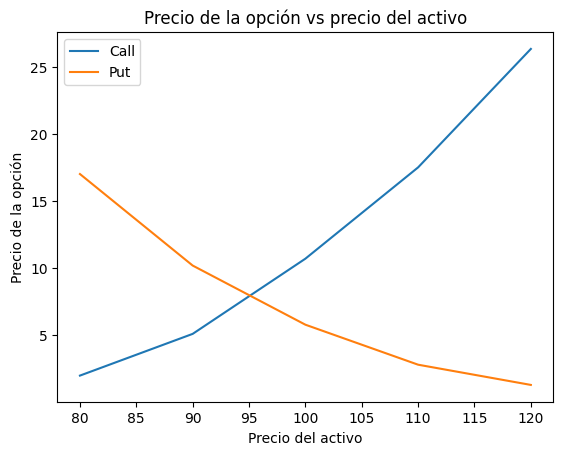

In [ ]:
plt.plot(tabla_call["Precio del activo"], tabla_call["Precio Call"], label="Call")
plt.plot(tabla_put["Precio del activo"], tabla_put["Precio Put"], label="Put")

plt.xlabel("Precio del activo")
plt.ylabel("Precio de la opción")
plt.title("Precio de la opción vs precio del activo")
plt.legend()

plt.show()

Precio de la opción vs strike

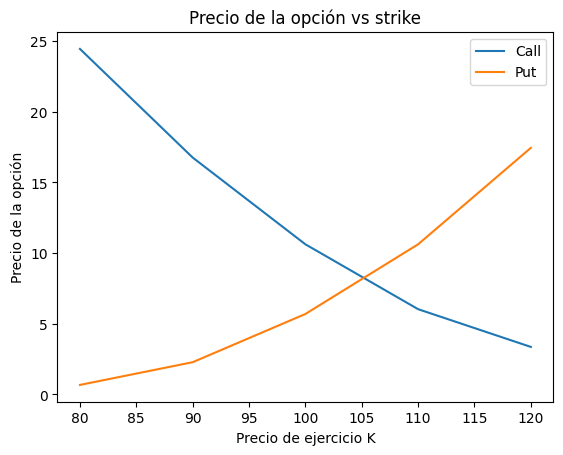

In [33]:
plt.plot(tabla_call["Strike"], tabla_call["Precio Call"], label="Call")
plt.plot(tabla_put["Strike"], tabla_put["Precio Put"], label="Put")

plt.xlabel("Precio de ejercicio K")
plt.ylabel("Precio de la opción")
plt.title("Precio de la opción vs strike")
plt.legend()

plt.show()


Precio de la opción vs volatilidad

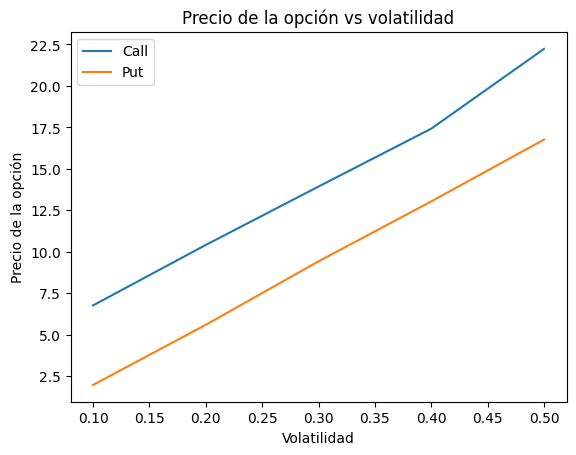

In [37]:
plt.plot(tabla_call["Volatilidad"], tabla_call["Precio Call"], label="Call")
plt.plot(tabla_put["Volatilidad"], tabla_put["Precio Put"], label="Put")

plt.xlabel("Volatilidad")
plt.ylabel("Precio de la opción")
plt.title("Precio de la opción vs volatilidad")
plt.legend()

plt.show()

Precio de la opción vs tiempo

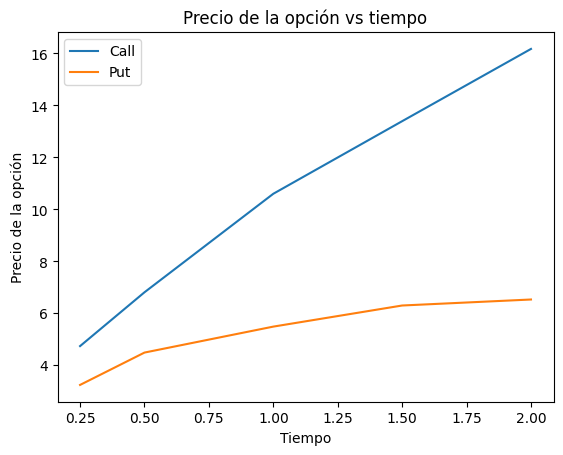

In [41]:
plt.plot(tabla_call["Tiempo"], tabla_call["Precio Call"], label="Call")
plt.plot(tabla_put["Tiempo"], tabla_put["Precio Put"], label="Put")

plt.xlabel("Tiempo")
plt.ylabel("Precio de la opción")
plt.title("Precio de la opción vs tiempo")
plt.legend()

plt.show()

Precio de la opción vs rendimiento

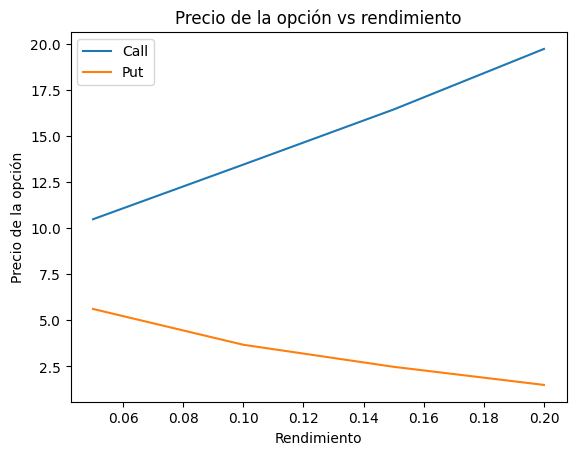

In [44]:
plt.plot(tabla_call["Rendimiento"], tabla_call["Precio Call"], label="Call")
plt.plot(tabla_put["Rendimiento"], tabla_put["Precio Put"], label="Put")

plt.xlabel("Rendimiento")
plt.ylabel("Precio de la opción")
plt.title("Precio de la opción vs rendimiento")
plt.legend()

plt.show()

### *Parte 4. Interpretación*

Precio del activo

**¿Por qué una call aumenta cuando aumenta el precio de la acción?** 

Porque la opción call da el derecho de comprar la acción a un precio acordado. Si el precio de la acción sube, la opción se vuelve más conveniente y por eso aumenta su valor.

**¿Por qué una put se comporta de manera distinta?**

Porque una put da el derecho de vender a un precio determinado. Si el precio de la acción baja, la put se vuelve más conveniente, por eso su valor aumenta cuando el precio del activo disminuye.

Volatilidad

**¿Por qué una mayor incertidumbre aumenta o disminuye el valor de la opción?**

Una mayor volatilidad significa que el precio puede cambiar más. Esto aumenta la posibilidad de que la opción termine siendo favorable para el inversionista, por lo que normalmente aumenta el valor tanto de la call como de la put.

Tiempo

**¿Siempre es deseable tener más tiempo?**

En general sí, porque al tener más tiempo hay más posibilidades de que el precio del activo cambie de manera favorable antes del vencimiento.

**¿Para quién resulta favorable?**

Principalmente para quien compra la opción, ya que tiene más tiempo para que la call o la put llegue a generar una ganancia.

Strike

**¿Cómo modifica el strike la probabilidad de terminar in-the-money?**

El strike es el precio al que se puede comprar o vender el activo. En una call, entre más bajo sea el strike, mayor es la posibilidad de terminar in-the-money. En una put ocurre lo contrario: un strike más alto puede aumentar esa posibilidad.

**Definir in-the-money**

In-the-money significa que la opción tiene valor porque ejercerla sería conveniente. En una call ocurre cuando el precio del activo es mayor que el strike, y en una put cuando el precio del activo es menor que el strike.

### *Parte 4. Comparación con el mercado*

Yo consideraría muy importante monitorear el precio del activo, porque en los resultados se observa que afecta directamente el valor de las opciones. Cuando aumenta el precio del activo, la call aumenta, mientras que la put disminuye. Por eso, conocer los movimientos del precio ayudaría a tomar mejores decisiones sobre qué tipo de opción utilizar.